<div style="text-align:center; padding:30px; background:linear-gradient(135deg,#1a1a2e,#16213e,#0f3460); border-radius:16px; color:white;">
  <h1 style="font-size:2.4em; margin-bottom:8px;">🤟 Sign Language Translation System</h1>
  <h3 style="color:#e94560; margin-top:0;">Graduation Project — Deep Learning & Computer Vision</h3>
  <hr style="border-color:#e94560; width:60%; margin:20px auto;">
  <table style="margin:auto; color:#ccc; font-size:1em;">
    <tr><td><b>Domain</b></td><td style="padding-left:20px;">Deep Learning · Computer Vision · Speech Synthesis</td></tr>
    <tr><td><b>Framework</b></td><td style="padding-left:20px;">TensorFlow / Keras · MediaPipe · OpenCV</td></tr>
    <tr><td><b>Environment</b></td><td style="padding-left:20px;">Google Colab (GPU recommended)</td></tr>
    <tr><td><b>Input</b></td><td style="padding-left:20px;">Sign Language Video or Live Webcam</td></tr>
    <tr><td><b>Output</b></td><td style="padding-left:20px;">Predicted Text + Text-to-Speech Audio</td></tr>
  </table>
</div>

---

## 📌 Project Pipeline

```
┌──────────────────────────────────────────────────────────────────────┐
│                        SIGN LANGUAGE TRANSLATION                     │
│                                                                      │
│  Video / Webcam → Frame Extraction → MediaPipe Landmark Detection    │
│       → Keypoint Sequence → LSTM+Attention Model → Sign Label        │
│       → Display Text Under Video → Text-to-Speech Audio              │
└──────────────────────────────────────────────────────────────────────┘
```

## 📋 Table of Contents
1. Install Dependencies  
2. Import Libraries & Global Config  
3. Mount Google Drive & Dataset Setup  
4. Unzip Dataset Automatically  
5. Explore & Understand the Dataset  
6. Feature Extraction with MediaPipe  
7. Build Dataset Arrays (Keypoints → Numpy)  
8. Preprocessing & Train/Val Split  
9. Model Architecture (LSTM + Attention)  
10. Train the Model  
11. Evaluation — Metrics, Graphs & Confusion Matrix  
12. Save & Load the Model  
13. Inference on Uploaded Video  
14. Real-Time Webcam Prediction  
15. Text-to-Speech Integration  
16. End-to-End Demo Widget  


---
## 📦 Section 1 — Install Dependencies

In [1]:
# =============================================
#  CRITICAL FIX: Downgrade NumPy + Reinstall
# =============================================

#import subprocess, sys


# Downgrade NumPy to version 1.x (most stable with MediaPipe)
#!pip uninstall -y numpy -q
#!pip install "numpy==1.26.4" -q

# Reinstall key packages with compatible versions
#!pip install --force-reinstall -q \
    #mediapipe==0.10.14 \
    #tensorflow==2.15.0 \
    #tensorflow-probability==0.23.0 \
    #opencv-python-headless \
    #scikit-learn


🛠️  Fixing NumPy compatibility...


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0)
ERROR: No matching distribution found for tensorflow==2.15.0
✅ Fix applied. Now restart the runtime.
🔄 Go to: **Runtime → Restart session** (Ctrl + M + .)


In [16]:
#pip install --force-reinstall pyarrow scikit-learn numpy --quiet

Note: you may need to restart the kernel to use updated packages.


In [1]:
#!pip install tensorflow

In [1]:
import os
import re
import cv2
import torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm
from gtts import gTTS

from arabic_reshaper import reshape
from bidi.algorithm import get_display

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers


BASE         = Path("/teamspace/studios/this_studio/data")
TRAIN_DIR    = BASE / "train"
TEST_DIR     = BASE / "test"
FEATURES_DIR = BASE / "features"
MODELS_DIR   = BASE / "models"

FEATURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CFG = {
    "MAX_FRAMES" : 30,
    "N_KEYPOINTS": 258,
    "BATCH_SIZE" : 32,
    "EPOCHS"     : 30,
    "LR"         : 1e-4,
    "PATIENCE"   : 5,
}

print("✅ Config OK")
for name, path in [("BASE",BASE),("TRAIN_DIR",TRAIN_DIR),("TEST_DIR",TEST_DIR)]:
    print(f"   {name}: exists={path.exists()}")

I0000 00:00:1779357072.523059    8008 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779357094.577356    8008 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


✅ Config OK
   BASE: exists=True
   TRAIN_DIR: exists=True
   TEST_DIR: exists=True


In [3]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

False
No GPU


In [ ]:
BASE = Path("/teamspace/studios/this_studio")

DATA_DIR      = BASE / "data"
TRAIN_DIR     = BASE / "general_train"
TEST_DIR      = BASE / "general_test"

FEATURES_DIR  = BASE / "features"
MODELS_DIR    = BASE / "models"
UPLOADS_DIR   = BASE / "uploads"

FEATURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)
UPLOADS_DIR.mkdir(exist_ok=True)

print(" Paths Ready")

 Paths Ready


In [3]:
# ================================================
# Section 2: Load Labels
# ================================================

import pandas as pd
from pathlib import Path

labels_path = Path("/teamspace/studios/this_studio/data/KARSL-502_Labels.xlsx")

if labels_path.exists():
    df_labels = pd.read_excel(labels_path)

    label_dict = dict(zip(df_labels['SignID'].astype(str), df_labels['Sign-Arabic'].astype(str)))

    label_names = df_labels['Sign-Arabic'].astype(str).tolist()
    NUM_CLASSES = len(label_names)

    print(f" Labels loaded: {NUM_CLASSES} إشارة")
    print(f"الأعمدة: {list(df_labels.columns)}")
    print(f"مثال: SignID '1' = '{label_dict.get('1')}'")
    display(df_labels[['SignID', 'Sign-Arabic', 'Sign-English']].head(10))
else:
    print("❌ ملف الـ Labels غير موجود!")

 Labels loaded: 502 إشارة
الأعمدة: ['SignID', 'Sign-Arabic', 'Sign-English']
مثال: SignID '1' = '0'


,SignID,Sign-Arabic,Sign-English
0,1,0,0
1,2,1,1
2,3,2,2
3,4,3,3
4,5,4,4
5,6,5,5
6,7,6,6
7,8,7,7
8,9,8,8
9,10,9,9


In [ ]:
import re, pandas as pd
from pathlib import Path

BASE       = Path("/teamspace/studios/this_studio/data")
TRAIN_DIR  = BASE / "general_train"
TEST_DIR   = BASE / "general_test"

def collect_videos(root: Path, split: str) -> pd.DataFrame:
    rows = []
    for vid in root.rglob("*"):
        if vid.suffix.lower() not in {".mp4", ".mov", ".avi", ".mkv"}:
            continue
        nums    = re.findall(r"\d+", vid.stem.split("_(")[0])
        sign_id = str(int(nums[-1])) if nums else "0"
        rows.append({
            "path"    : str(vid),
            "sign_id" : sign_id,
            "label"   : label_dict.get(sign_id, "Unknown"),
            "split"   : split,
            "filename": vid.name,
        })
    return pd.DataFrame(rows).sort_values("sign_id").reset_index(drop=True)

df_train = collect_videos(TRAIN_DIR, "train")
df_test  = collect_videos(TEST_DIR,  "test")

print(f"✅ Train: {len(df_train)} فيديو")
print(f"✅ Test : {len(df_test)} فيديو")
print(f"⚠️  Unknown — Train: {(df_train.label=='Unknown').sum()} | Test: {(df_test.label=='Unknown').sum()}")
display(df_train[["filename","sign_id","label"]].head(8))

✅ Train: 22899 فيديو
✅ Test : 9268 فيديو
⚠️  Unknown — Train: 0 | Test: 0


,filename,sign_id,label
0,01_01_0001_(10_11_16_16_20_34)_c.mp4,1,0
1,01_01_0001_(10_11_16_16_20_36)_c.mp4,1,0
2,01_01_0001_(10_11_16_16_20_42)_c.mp4,1,0
3,01_01_0001_(10_11_16_16_20_44)_c.mp4,1,0
4,01_01_0001_(10_11_16_16_20_46)_c.mp4,1,0
5,01_01_0001_(10_11_16_16_20_48)_c.mp4,1,0
6,01_01_0001_(10_11_16_16_20_50)_c.mp4,1,0
7,01_01_0001_(10_11_16_16_20_51)_c.mp4,1,0


In [10]:
import shutil
from pathlib import Path
from IPython.display import Video, display

video_path = '/teamspace/studios/this_studio/data/general_train/0026/01_01_0026_(17_11_16_16_52_57)_c.mp4'

new_path = Path(video_path).name
shutil.copy(video_path, new_path)

print(f"✅ تم نسخ الفيديو: {new_path}")
print(f"📁 حجم الفيديو: {Path(new_path).stat().st_size / (1024*1024):.2f} MB")

display(Video(new_path, width=800, height=500, embed=False))


✅ تم نسخ الفيديو: 01_01_0026_(17_11_16_16_52_57)_c.mp4
📁 حجم الفيديو: 0.63 MB


In [11]:
#!pip install tensorflow

📽️  إجمالي عدد الـ Frames: 25


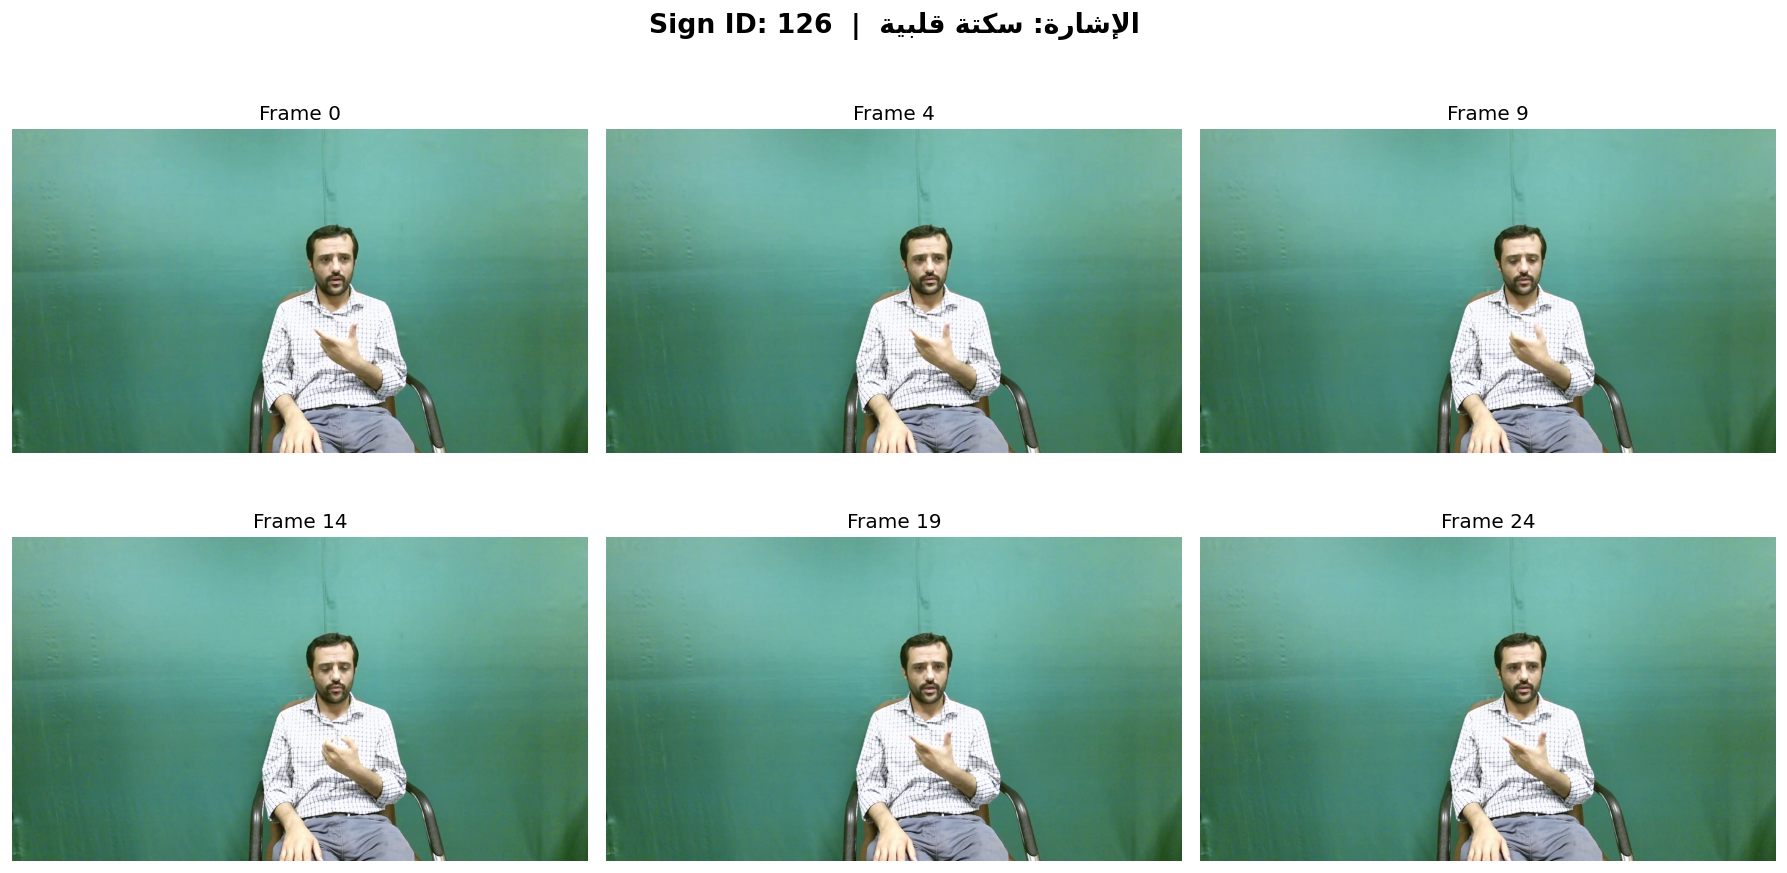

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from arabic_reshaper import reshape
from bidi.algorithm import get_display

video_path = '/teamspace/studios/this_studio/data/general_train/0026/01_01_0026_(17_11_16_16_52_57)_c.mp4'

# قراءة الفيديو
cap = cv2.VideoCapture(video_path)
frames = []

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

cap.release()

print(f"📽️  إجمالي عدد الـ Frames: {len(frames)}")

indices = np.linspace(0, len(frames)-1, 6, dtype=int)

label = "سكتة قلبية"   
sign_id = 126

reshaped = reshape(f"الإشارة: {label}  |  Sign ID: {sign_id}")
bidi_txt = get_display(reshaped)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=120)
axes = axes.flatten()

for i, idx in enumerate(indices):
    axes[i].imshow(frames[idx])
    axes[i].set_title(f"Frame {idx}", fontsize=12)
    axes[i].axis("off")

plt.suptitle(bidi_txt, fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [26]:
import cv2
import numpy as np
import os
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.utils import Sequence

# ========================== إعدادات ==========================
base_path = '/teamspace/studios/this_studio/data/general_train'
frames_per_video = 16
img_size = (112, 112)        # مهم: صغّريه شوية
batch_size = 4               # ابدئي بـ 4 أو 6             
max_videos_per_class = None      
# ============================================================

class_folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]
class_folders.sort()
selected_classes = selected_classes[:100]   # أو اختاري أكثر تكراراً

print(f"📊 عدد الكلاسات المكتشفة: {len(selected_classes)}")
print(f"أول 10 كلاسات: {selected_classes[:10]}")

# ====================== Data Generator ======================
class SignLanguageGenerator(Sequence):
    def __init__(self, base_path, selected_classes, frames_per_video=16, img_size=(128,128), 
                 batch_size=8, max_videos_per_class=None, shuffle=True):
        self.base_path = base_path
        self.selected_classes = selected_classes
        self.frames_per_video = frames_per_video
        self.img_size = img_size
        self.batch_size = batch_size
        self.shuffle = shuffle
        
        self.video_list = []
        self.labels = []
        
        for cls_idx, cls in enumerate(selected_classes):
            cls_path = os.path.join(base_path, cls)
            videos = [v for v in os.listdir(cls_path) if v.endswith(('.mp4', '.MP4'))]
            if max_videos_per_class:
                videos = videos[:max_videos_per_class]
            
            for v in videos:
                self.video_list.append(os.path.join(cls_path, v))
                self.labels.append(cls_idx)
        
        self.video_list = np.array(self.video_list)
        self.labels = np.array(self.labels)
        self.on_epoch_end()
        
        print(f"✅ إجمالي فيديوهات للتدريب: {len(self.video_list)}")
    
    def __len__(self):
        return int(np.ceil(len(self.video_list) / self.batch_size))
    
    def on_epoch_end(self):
        if self.shuffle:
            idx = np.random.permutation(len(self.video_list))
            self.video_list = self.video_list[idx]
            self.labels = self.labels[idx]
    
    def __getitem__(self, index):
        batch_videos = self.video_list[index*self.batch_size:(index+1)*self.batch_size]
        batch_labels = self.labels[index*self.batch_size:(index+1)*self.batch_size]
        
        X_batch = []
        for vid_path in batch_videos:
            cap = cv2.VideoCapture(vid_path)
            frames = []
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            step = max(1, total_frames // self.frames_per_video)
            
            for i in range(self.frames_per_video):
                cap.set(cv2.CAP_PROP_POS_FRAMES, i * step)
                ret, frame = cap.read()
                if not ret:
                    break
                frame = cv2.resize(frame, self.img_size)
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = frame / 255.0
                frames.append(frame)
            cap.release()
            
            # لو الفيديو قصير
            while len(frames) < self.frames_per_video:
                frames.append(frames[-1] if frames else np.zeros((*self.img_size, 3)))
            
            X_batch.append(frames)
        
        return np.array(X_batch, dtype=np.float32), np.array(batch_labels, dtype=np.int32)


train_generator = SignLanguageGenerator(
    base_path=base_path,
    selected_classes=selected_classes,
    frames_per_video=frames_per_video,
    img_size=img_size,
    batch_size=batch_size,
    max_videos_per_class=max_videos_per_class
)

📊 عدد الكلاسات المكتشفة: 100
أول 10 كلاسات: ['0001', '0001-0070', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009']
✅ إجمالي فيديوهات للتدريب: 4165


In [28]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# ====================== موديل محسن بـ Transfer Learning ======================
base_model = EfficientNetB0(
    weights='imagenet', 
    include_top=False, 
    input_shape=(img_size[0], img_size[1], 3)
)
base_model.trainable = False   # Freezes the CNN first

model = models.Sequential([
    layers.TimeDistributed(base_model, input_shape=(frames_per_video, img_size[0], img_size[1], 3)),
    layers.TimeDistributed(layers.GlobalAveragePooling2D()),
    
    layers.LSTM(512, return_sequences=True, dropout=0.3),
    layers.LSTM(256, dropout=0.4),
    
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    #layers.Dropout(0.5),
    layers.Dense(502, activation='softmax')   # 502 classes
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_16             │ (None, 16, 4, 4, 1280) │     4,049,571 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_17             │ (None, 16, 1280)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 16, 512)        │     3,672,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 256)            │       787,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 502)            │       257,526 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,900,249 (33.95 MB)

 Trainable params: 4,849,654 (18.50 MB)

 Non-trainable params: 4,050,595 (15.45 MB)

In [29]:
from tensorflow.keras.mixed_precision import set_global_policy
set_global_policy('mixed_float16')   # مهم جداً لتوفير الذاكرة

train_generator = SignLanguageGenerator(
    base_path=base_path,
    selected_classes=selected_classes,   
    frames_per_video=frames_per_video,
    img_size=img_size,
    batch_size=batch_size,
    max_videos_per_class=None,  
    shuffle=True
)

✅ إجمالي فيديوهات للتدريب: 4165


In [37]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

In [ ]:
history = model.fit(
    train_generator,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1779363236.779989    8008 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


1042/1042 ━━━━━━━━━━━━━━━━━━━━ 4421s 4s/step - accuracy: 0.0074 - loss: 6.2950 - learning_rate: 1.0000e-04
Epoch 2/20


/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/keras/src/callbacks/early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_accuracy` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)
/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/keras/src/callbacks/callback_list.py:171: UserWarning: Learning rate reduction is conditioned on metric `val_accuracy` which is not available. Available metrics are: accuracy,loss,learning_rate.
  callback.on_epoch_end(epoch, logs)


 131/1042 ━━━━━━━━━━━━━━━━━━━━ 1:05:55 4s/step - accuracy: 0.0127 - loss: 6.0596

In [25]:
final_epoch = len(history.history['accuracy']) - 1

train_acc = history.history['accuracy'][final_epoch] * 100
val_acc = history.history['val_accuracy'][final_epoch] * 100

train_loss = history.history['loss'][final_epoch]
val_loss = history.history['val_loss'][final_epoch]

print(f" Training Accuracy   : {train_acc:.2f}%")
print(f" Validation Accuracy : {val_acc:.2f}%")
print(f" Training Loss       : {train_loss:.4f}")
print(f" Validation Loss     : {val_loss:.4f}")

 Training Accuracy   : 26.39%
 Validation Accuracy : 33.33%
 Training Loss       : 1.2354
 Validation Loss     : 1.0995


In [15]:
#!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.4/780.4 MB 634.2 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 81.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 91.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 76.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 31.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 57.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 9.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 15.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 8.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196

In [ ]:
# ============================================================
# 🔥 MERGED VERSION
# استخدام Pipeline الـ Translator على كامل Dataset KArSL-502
# ============================================================

# الفكرة:
# هنستخدم نفس أسلوب translator
# لكن بدل sample واحد → هنشغل على كامل الـ Dataset
# مع الاحتفاظ بالفحص البصري + DataLoader + Label Mapping

# ============================================================
# SECTION 1 — IMPORTS
# ============================================================

import os
import re
import cv2
import torch
import numpy as np
import pandas as pd
import mediapipe as mp
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm
from PIL import Image

from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from arabic_reshaper import reshape
from bidi.algorithm import get_display

# ============================================================
# SECTION 2 — CONFIG
# ============================================================

CFG = {
    "DATASET_PATH": "/content/KArSL-502",
    "MAX_FRAMES": 30,
    "IMG_SIZE": 224,
    "BATCH_SIZE": 8,
    "NUM_WORKERS": 2,

    # Mediapipe Features
    "N_KEYPOINTS": 258,

    # Output
    "FEATURES_DIR": "/content/sign_features"
}

Path(CFG["FEATURES_DIR"]).mkdir(parents=True, exist_ok=True)

# ============================================================
# SECTION 3 — LOAD LABELS
# ============================================================

labels_path = Path("/content/drive/MyDrive/KArSL-502/KARSL-502_Labels.xlsx")

df_labels = pd.read_excel(labels_path)

label_dict = dict(
    zip(
        df_labels['SignID'].astype(str),
        df_labels['Sign-Arabic'].astype(str)
    )
)

print("✅ Labels Loaded")
print("عدد الكلمات:", len(label_dict))

# ============================================================
# SECTION 4 — COLLECT VIDEOS
# ============================================================

LOCAL_TRAIN = Path("/content/KArSL-502/train")
LOCAL_TEST  = Path("/content/KArSL-502/test")

def collect_videos(root_path: Path, split: str):

    rows = []

    extensions = ['*.mp4', '*.mov', '*.avi', '*.mkv']

    for ext in extensions:

        for vid in root_path.rglob(ext):

            filename = vid.name
            stem = vid.stem

            prefix = stem.split('_(')[0]

            nums = re.findall(r'\d+', prefix)

            sign_id = str(int(nums[-1])) if nums else "0"

            label = label_dict.get(sign_id, "Unknown")

            rows.append({
                "path": str(vid),
                "sign_id": sign_id,
                "label": label,
                "split": split,
                "filename": filename
            })

    return pd.DataFrame(rows)

df_train = collect_videos(LOCAL_TRAIN, "train")
df_test  = collect_videos(LOCAL_TEST, "test")

print("✅ Train Videos:", len(df_train))
print("✅ Test Videos :", len(df_test))

# ============================================================
# SECTION 5 — LABEL ENCODER
# ============================================================

label_encoder = LabelEncoder()

all_labels = sorted(df_train['sign_id'].unique(), key=int)

label_encoder.fit(all_labels)

NUM_CLASSES = len(all_labels)

print("✅ NUM_CLASSES =", NUM_CLASSES)

# ============================================================
# SECTION 6 — MEDIAPIPE SETUP
# ============================================================

mp_holistic = mp.solutions.holistic

holistic = mp_holistic.Holistic(
    static_image_mode=False,
    model_complexity=1,
    smooth_landmarks=True,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
)

# ============================================================
# SECTION 7 — KEYPOINT EXTRACTION
# ============================================================

def extract_keypoints(results):

    pose = np.array(
        [[res.x, res.y, res.z, res.visibility]
         for res in results.pose_landmarks.landmark]
    ).flatten() if results.pose_landmarks else np.zeros(33 * 4)

    face = np.array(
        [[res.x, res.y, res.z]
         for res in results.face_landmarks.landmark]
    ).flatten() if results.face_landmarks else np.zeros(468 * 3)

    lh = np.array(
        [[res.x, res.y, res.z]
         for res in results.left_hand_landmarks.landmark]
    ).flatten() if results.left_hand_landmarks else np.zeros(21 * 3)

    rh = np.array(
        [[res.x, res.y, res.z]
         for res in results.right_hand_landmarks.landmark]
    ).flatten() if results.right_hand_landmarks else np.zeros(21 * 3)

    return np.concatenate([pose, face, lh, rh])

# ============================================================
# SECTION 8 — VIDEO TO FEATURES
# ============================================================

def process_video(video_path):

    cap = cv2.VideoCapture(video_path)

    frames = []

    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            break

        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        results = holistic.process(image)

        keypoints = extract_keypoints(results)

        frames.append(keypoints)

    cap.release()

    # padding / truncation
    if len(frames) >= CFG["MAX_FRAMES"]:
        indices = np.linspace(
            0,
            len(frames) - 1,
            CFG["MAX_FRAMES"],
            dtype=int
        )

        frames = [frames[i] for i in indices]

    else:

        while len(frames) < CFG["MAX_FRAMES"]:
            frames.append(np.zeros_like(frames[0]))

    return np.array(frames)

# ============================================================
# SECTION 9 — BUILD FEATURES DATASET
# ============================================================

X_train = []
y_train = []

print("🔥 Extracting TRAIN features...")

for _, row in tqdm(df_train.iterrows(), total=len(df_train)):

    try:

        features = process_video(row['path'])

        label = label_encoder.transform([row['sign_id']])[0]

        X_train.append(features)
        y_train.append(label)

    except Exception as e:

        print("❌ Error:", row['filename'])
        print(e)

X_train = np.array(X_train)
y_train = np.array(y_train)

print("✅ TRAIN FEATURES:", X_train.shape)

# ============================================================
# SECTION 10 — TEST FEATURES
# ============================================================

X_test = []
y_test = []

print("🔥 Extracting TEST features...")

for _, row in tqdm(df_test.iterrows(), total=len(df_test)):

    try:

        features = process_video(row['path'])

        label = label_encoder.transform([row['sign_id']])[0]

        X_test.append(features)
        y_test.append(label)

    except Exception as e:

        print("❌ Error:", row['filename'])
        print(e)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("✅ TEST FEATURES:", X_test.shape)

# ============================================================
# SECTION 11 — SAVE FEATURES
# ============================================================

np.save(f"{CFG['FEATURES_DIR']}/X_train.npy", X_train)
np.save(f"{CFG['FEATURES_DIR']}/y_train.npy", y_train)

np.save(f"{CFG['FEATURES_DIR']}/X_test.npy", X_test)
np.save(f"{CFG['FEATURES_DIR']}/y_test.npy", y_test)

print("✅ Features Saved")

# ============================================================
# SECTION 12 — VISUAL INSPECTION
# ============================================================

sample_row = df_train.iloc[0]

sample_video_path = sample_row['path']

sample_label = sample_row['label']

cap = cv2.VideoCapture(sample_video_path)

frames = []

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    frame = cv2.resize(frame, (224, 224))

    frames.append(frame)

cap.release()

indices = np.linspace(0, len(frames)-1, 6, dtype=int)

reshaped_text = reshape(f"الإشارة: {sample_label}")
bidi_text = get_display(reshaped_text)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()

for i, idx in enumerate(indices):

    axes[i].imshow(frames[idx])

    axes[i].set_title(f"Frame {idx}")

    axes[i].axis("off")

plt.suptitle(bidi_text, fontsize=18)

plt.tight_layout()

plt.show()

# ============================================================
# SECTION 13 — FINAL CHECK
# ============================================================

print("\n==============================")
print("🔥 FINAL CHECK")
print("==============================")

print("train:", len(X_train))
print("test :", len(X_test))

print("\n🔥 NUM_CLASSES =", NUM_CLASSES)

print("✅ X_train:", X_train.shape)
print("✅ y_train:", y_train.shape)

print("✅ X_test :", X_test.shape)
print("✅ y_test :", y_test.shape)

print("\n🎉 EVERYTHING IS READY")

---
## 💾 Section 7 — Build Dataset Arrays (Keypoints → NumPy)

---
## 🔧 Section 8 — Preprocessing & Train / Validation Split

---
## 🧠 Section 9 — Model Architecture (Bidirectional LSTM + Attention)

---
## 🏋️ Section 10 — Train the Model

---
## 📈 Section 11 — Evaluation — Metrics, Loss/Accuracy Graphs & Confusion Matrix

---
## 💾 Section 12 — Save & Load the Model

---
## 🔮 Section 13 — Inference Engine & Text-to-Speech

---
## 📤 Section 14 — Inference on Uploaded Video File

---
## 📷 Section 15 — Real-Time Webcam Prediction

---
## 🎛️ Section 16 — End-to-End Interactive Demo Widget

---
## 🎓 Section 17 — Project Summary & Conclusions

### ✅ What Was Built

| Component | Details |
|---|---|
| **Feature Extraction** | MediaPipe Holistic — 258-dim keypoint vector per frame |
| **Model Architecture** | Bidirectional LSTM + Self-Attention + Dense head |
| **Training** | EarlyStopping, ReduceLROnPlateau, ModelCheckpoint |
| **Evaluation** | Accuracy, Top-3 Accuracy, Classification Report, Confusion Matrix |
| **Inference** | Video upload + Live Webcam (Google Colab JS bridge) |
| **Speech** | gTTS text-to-speech, auto-played after every prediction |
| **UI** | Interactive ipywidgets demo panel |

### 🚀 Possible Improvements

- **Larger Dataset** — more video samples per class improve generalisation  
- **Data Augmentation** — random flip, speed perturbation, noise injection on keypoints  
- **Transformer Encoder** — replace LSTM with a temporal transformer for longer sequences  
- **CTC Decoding** — support continuous (sentence-level) sign language recognition  
- **Mobile Deployment** — convert to TFLite for on-device real-time inference  
- **Multi-language TTS** — support Arabic, Spanish, French, etc.  

### 📚 References

1. MediaPipe Holistic — Google AI (2020)  
2. *Sign Language Recognition Using Deep Learning* — IEEE (2022)  
3. Hochreiter & Schmidhuber — *Long Short-Term Memory*, Neural Computation (1997)  
4. Vaswani et al. — *Attention Is All You Need*, NeurIPS (2017)  
5. TensorFlow / Keras Official Documentation — tensorflow.org  

---
<div style="text-align:center; padding:20px; background:#f8f9fa; border-radius:10px;">
  <h3>🤟 Sign Language Translation System</h3>
  <p>Graduation Project — Deep Learning & Computer Vision</p>
  <p style="color:#e94560; font-weight:bold;">Built with TensorFlow · MediaPipe · OpenCV · gTTS</p>
</div>
